# Parte 2: mejora mediante ajuste de mBERT

El modelo anterior obtuvo **0,70383 en Kaggle**, según el resultado informado por el grupo.
Sus embeddings estaban congelados. Ahora entrenamos las capas contextuales de mBERT junto
con un MLP, para que la representación aprenda los contrastes y las negaciones de estas reseñas.
Seguimos usando exclusivamente un **encoder BERT**; no hay generación de texto.

Conservamos los mismos IDs de validación de la primera comparación. El archivo `eval.csv`
no se usa durante entrenamiento, aumento, selección de épocas ni elección de hiperparámetros.
El nuevo score público solo se conocerá después de enviar los CSV a Kaggle.

## 1. Librerías y configuración

En Kaggle: agregar los CSV de la competencia, activar una GPU y ejecutar este notebook.
Si no está el archivo `particion.csv`, se reproduce la división de la primera versión
con la misma detección de idioma, estratificación y semilla. Para ello se necesita langid
(la celda opcional de instalación permite agregarlo en Kaggle).


**Resultados públicos informados posteriormente por el grupo:** `particion80` obtuvo **0,87180** y `full` obtuvo **0,87721**. El candidato `full` es el mejor envío público confirmado; sus resultados están registrados en `output/parte2/mejora/registro_kaggle.csv`.

In [1]:
# Solo si langid no está instalado:
# %pip install langid==1.1.6


In [2]:
from pathlib import Path
import argparse
import gc
import hashlib
import importlib.metadata
import json
import os
import random
import shutil
import sys
import time

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoConfig, AutoModel, AutoTokenizer, DataCollatorWithPadding
from transformers import get_linear_schedule_with_warmup
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
torch.set_num_threads(min(8, os.cpu_count() or 1))
torch.use_deterministic_algorithms(True)

SEMILLA = 42
CLASES = ["negativo", "neutral", "positivo"]
MODELO_BASE = "google-bert/bert-base-multilingual-cased"
REVISION = "3f076fdb1ab68d5b2880cb87a0886f315b8146f8"
MAX_LENGTH = 192
BATCH_SIZE = 16
MAX_EPOCAS = 4
PACIENCIA = 2
LR_ENCODER = 2e-5
LR_CABEZA = 3e-4
FRACCION_AUMENTO = 0.50
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DISPOSITIVO.type == "cuda"
TIPO_AMP = torch.bfloat16 if AMP and torch.cuda.is_bf16_supported() else torch.float16

BASE = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
SALIDA = BASE / "output/parte2/mejora"
MODELOS = BASE / "models/parte2/finetuning"
SALIDA.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)
EXPERIMENTOS = [
    {"nombre": "p2_exp06_mbert_ajustado", "aumento": False},
    {"nombre": "p2_exp07_mbert_ajustado_aumento", "aumento": True},
]


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Funciones de datos

Reutilizamos el aumento tipográfico de la primera versión. Cada copia conserva su etiqueta
y su ID de origen. Solo se aumenta la partición de entrenamiento durante la comparación.
Las negaciones no se modifican. El efecto se mide con el mismo encoder y los mismos parámetros.


In [3]:
def fijar_semilla():
    random.seed(SEMILLA)
    np.random.seed(SEMILLA)
    torch.manual_seed(SEMILLA)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEMILLA)


def aumentar(datos):
    # Una copia por reseña seleccionada; un intercambio de letras dentro de una palabra larga.
    import re
    protegidas = set("no nunca jamás jamas ni nada nadie ninguno ninguna ningún ningun tampoco sin not never neither nor nothing nobody nowhere without don't doesn't didn't isn't wasn't wouldn't couldn't shouldn't cannot can't won't nao não nunca jamais nem nada ninguém ninguem nenhum nenhuma sem ne pas jamais rien personne aucun aucune sans non".split())
    generador = random.Random(SEMILLA)
    originales = set(datos["text"])
    filas = []
    for _, fila in datos.sample(frac=FRACCION_AUMENTO, random_state=SEMILLA).iterrows():
        texto = fila["text"]
        opciones = []
        for palabra in re.finditer(r"[^\W\d_]+", texto):
            termino = palabra.group()
            if len(termino) >= 7 and termino.lower() not in protegidas:
                posiciones = [i for i in range(1, len(termino) - 2) if termino[i] != termino[i + 1]]
                if posiciones:
                    opciones.append((palabra, posiciones))
        if not opciones:
            continue
        palabra, posiciones = generador.choice(opciones)
        i = generador.choice(posiciones)
        letras = list(palabra.group())
        letras[i], letras[i + 1] = letras[i + 1], letras[i]
        nuevo = texto[:palabra.start()] + "".join(letras) + texto[palabra.end():]
        if nuevo not in originales:
            filas.append({"id_origen": int(fila["id"]), "text": nuevo, "label": fila["label"]})
    return pd.DataFrame(filas, columns=["id_origen", "text", "label"]).drop_duplicates("text")


def reconstruir_particion(train):
    import re
    from langid.langid import LanguageIdentifier, model as modelo_idiomas
    detector = LanguageIdentifier.from_modelstring(modelo_idiomas, norm_probs=True)
    detector.set_languages(["es", "en", "pt", "fr"])
    es = set("compré compre llegó llego pedí pedi pero aunque estoy tengo funciona después despues".split())
    en = set("the this with bought arrived works although however really because very would".split())

    def idioma(texto):
        palabras = set(re.findall(r"[^\W\d_]+", texto.lower()))
        if len(palabras & es) >= 2 and len(palabras & en) >= 2:
            return "mixto_es_en"
        return detector.classify(texto)[0]

    particion = train[["id", "label"]].copy()
    particion["idioma_estimado"] = train["text"].map(idioma)
    estratos = particion["label"] + "_" + particion["idioma_estimado"]
    if estratos.value_counts().min() < 2:
        estratos = particion["label"]
    _, indices_val = train_test_split(np.arange(len(train)), test_size=0.20,
                                     random_state=SEMILLA, stratify=estratos)
    particion["particion"] = "entrenamiento"
    particion.loc[indices_val, "particion"] = "validacion"
    return particion


def cargar_datos():
    carpetas = [Path("data/parte2")]
    if Path("/kaggle/input").exists():
        carpetas += [p.parent for p in Path("/kaggle/input").rglob("train.csv")]
    candidatas = []
    for carpeta in carpetas:
        if all((carpeta / n).exists() for n in ["train.csv", "eval.csv", "sample_submission.csv"]):
            d = pd.read_csv(carpeta / "train.csv")
            if len(d) == 20466:
                candidatas.append(carpeta)
    if len(candidatas) != 1:
        raise ValueError("Agregar exactamente una carpeta con los datos oficiales de la parte 2.")
    carpeta = candidatas[0]
    train = pd.read_csv(carpeta / "train.csv")
    evaluar = pd.read_csv(carpeta / "eval.csv")
    sample = pd.read_csv(carpeta / "sample_submission.csv")
    assert len(evaluar) == len(sample) == 6781
    assert list(train.columns) == ["id", "text", "label"]
    assert list(evaluar.columns) == ["id", "text"]
    assert list(sample.columns) == ["id", "answer"]
    assert set(train["label"]) == set(CLASES)
    for d in [train, evaluar, sample]:
        assert d["id"].is_unique and not d.isna().any().any()
    assert set(evaluar["id"]) == set(sample["id"])
    assert not train["text"].duplicated().any()

    rutas = [Path("output/parte2/particion.csv"), Path("particion.csv")]
    if Path("/kaggle/input").exists():
        rutas += list(Path("/kaggle/input").rglob("particion.csv"))
    rutas = [p for p in rutas if p.exists()]
    particion = pd.read_csv(rutas[0]) if rutas else reconstruir_particion(train)
    assert particion["id"].is_unique and set(particion["id"]) == set(train["id"])
    assert set(particion["particion"]) == {"entrenamiento", "validacion"}
    datos = train.merge(particion[["id", "label", "idioma_estimado", "particion"]],
                        on=["id", "label"], validate="one_to_one")
    assert len(datos) == len(train)
    datos_train = datos[datos["particion"].eq("entrenamiento")].copy()
    datos_val = datos[datos["particion"].eq("validacion")].copy()
    assert len(datos_val) == 4094
    assert set(datos_train["text"]).isdisjoint(set(datos_val["text"]))
    particion.to_csv(SALIDA / "particion.csv", index=False)
    return carpeta, datos, datos_train, datos_val, evaluar, sample


## 3. Reseñas por lotes y arquitectura

El tokenizador es el mismo de mBERT. El padding se agrega por lote para ahorrar memoria.
Promediamos solo tokens del texto y concatenamos ese vector con CLS, como en el mejor MLP.
La cabeza tiene dos capas ocultas, ReLU y Dropout. La diferencia principal es que ahora
los doce bloques contextuales también reciben gradientes.

Conservamos congelada la tabla inicial de embeddings de palabras para reducir memoria
y mantener su vocabulario multilingüe. Sus representaciones contextuales sí cambian con
las capas Transformer que estamos entrenando. No hay que aprender un vocabulario nuevo.


In [4]:
class Resenas(Dataset):
    def __init__(self, datos, tokenizador, con_etiquetas=True):
        self.entradas = tokenizador(datos["text"].tolist(), truncation=True, max_length=MAX_LENGTH,
                                    return_special_tokens_mask=True)
        self.etiquetas = datos["label"].map({c: i for i, c in enumerate(CLASES)}).tolist() if con_etiquetas else None

    def __len__(self):
        return len(self.entradas["input_ids"])

    def __getitem__(self, indice):
        fila = {k: v[indice] for k, v in self.entradas.items()}
        if self.etiquetas is not None:
            fila["labels"] = self.etiquetas[indice]
        return fila


class ClasificadorResenas(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        dimension = encoder.config.hidden_size * 2
        self.cabeza = nn.Sequential(
            nn.Linear(dimension, 128), nn.ReLU(), nn.Dropout(0.20),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.20), nn.Linear(64, len(CLASES)),
        )

    def forward(self, special_tokens_mask, **entradas):
        ocultos = self.encoder(**entradas).last_hidden_state
        mascara = (entradas["attention_mask"].bool() & ~special_tokens_mask.bool()).unsqueeze(-1)
        promedio = (ocultos * mascara).sum(1) / mascara.sum(1).clamp(min=1)
        return self.cabeza(torch.cat([ocultos[:, 0, :], promedio], dim=1))


def nuevo_modelo():
    fijar_semilla()
    local = Path("models/parte2/mbert")
    fuente = str(local) if (local / "config.json").exists() else MODELO_BASE
    opciones = {"local_files_only": True} if fuente != MODELO_BASE else {"revision": REVISION}
    encoder = AutoModel.from_pretrained(fuente, **opciones)
    if encoder.config.model_type != "bert" or encoder.config.is_decoder or encoder.config.is_encoder_decoder:
        raise ValueError("Solo se permite el encoder mBERT indicado.")
    for parametro in encoder.embeddings.parameters():
        parametro.requires_grad = False
    return ClasificadorResenas(encoder).to(DISPOSITIVO)


def crear_lotes(datos, tokenizador, entrenamiento=False, con_etiquetas=True):
    return DataLoader(Resenas(datos, tokenizador, con_etiquetas), batch_size=BATCH_SIZE,
                      shuffle=entrenamiento, num_workers=0,
                      collate_fn=DataCollatorWithPadding(tokenizador),
                      generator=torch.Generator().manual_seed(SEMILLA))


def guardar_modelo(modelo, tokenizador, carpeta, informacion):
    carpeta.mkdir(parents=True, exist_ok=True)
    modelo.encoder.save_pretrained(carpeta / "encoder", safe_serialization=True)
    tokenizador.save_pretrained(carpeta / "encoder")
    torch.save({k: v.detach().cpu() for k, v in modelo.cabeza.state_dict().items()}, carpeta / "cabeza.pt")
    (carpeta / "configuracion.json").write_text(json.dumps(informacion, ensure_ascii=False, indent=2), encoding="utf-8")


def cargar_modelo(carpeta):
    encoder = AutoModel.from_pretrained(carpeta / "encoder", local_files_only=True)
    modelo = ClasificadorResenas(encoder)
    modelo.cabeza.load_state_dict(torch.load(carpeta / "cabeza.pt", weights_only=True, map_location="cpu"))
    return modelo.to(DISPOSITIVO).eval()


## 4. Entrenamiento y evaluación

Usamos AdamW y una tasa pequeña para las capas preentrenadas. La cabeza nueva aprende
más rápido. La tasa sube durante el primer 10% de los pasos y después baja gradualmente.
Limitamos la norma del gradiente para evitar actualizaciones demasiado grandes.

En GPU usamos precisión mixta para ahorrar memoria; esto no cambia la arquitectura.
En cada época medimos accuracy en las mismas 4.094 reseñas de validación. Guardamos
el mejor checkpoint por accuracy y usamos pérdida para resolver empates.


In [5]:
def evaluar_modelo(modelo, lotes, con_etiquetas=True):
    modelo.eval()
    reales, probabilidades = [], []
    costo, cantidad = 0.0, 0
    with torch.no_grad():
        for lote in lotes:
            lote = {k: v.to(DISPOSITIVO) for k, v in lote.items()}
            etiquetas = lote.pop("labels", None)
            with torch.autocast(DISPOSITIVO.type, dtype=TIPO_AMP, enabled=AMP):
                salidas = modelo(**lote)
            probabilidades.append(salidas.float().softmax(-1).cpu().numpy())
            if con_etiquetas:
                costo += nn.functional.cross_entropy(salidas.float(), etiquetas, reduction="sum").item()
                cantidad += len(etiquetas)
                reales.extend(etiquetas.cpu().tolist())
    probabilidades = np.concatenate(probabilidades)
    pred = probabilidades.argmax(1)
    return probabilidades, np.array(reales), costo / max(cantidad, 1)


def entrenar(config, datos_train, tokenizador, datos_val=None, epocas=MAX_EPOCAS, destino=None):
    modelo = nuevo_modelo()
    lotes_train = crear_lotes(datos_train, tokenizador, entrenamiento=True)
    lotes_val = crear_lotes(datos_val, tokenizador) if datos_val is not None else None
    optimizador = torch.optim.AdamW([
        {"params": [p for p in modelo.encoder.parameters() if p.requires_grad], "lr": LR_ENCODER},
        {"params": modelo.cabeza.parameters(), "lr": LR_CABEZA},
    ], weight_decay=0.01)
    # Mantener el plan de cuatro épocas también al reentrenar hasta una época anterior.
    pasos = MAX_EPOCAS * len(lotes_train)
    plan = get_linear_schedule_with_warmup(optimizador, int(pasos * 0.1), pasos)
    escalador = torch.amp.GradScaler("cuda", enabled=AMP and TIPO_AMP == torch.float16)
    mejor_acc, mejor_loss, mejor_epoca, sin_mejora = -1.0, float("inf"), 0, 0
    historial = []
    for epoca in range(1, epocas + 1):
        inicio = time.time()
        modelo.train()
        suma, n, aciertos = 0.0, 0, 0
        for paso, lote in enumerate(lotes_train, start=1):
            lote = {k: v.to(DISPOSITIVO) for k, v in lote.items()}
            etiquetas = lote.pop("labels")
            optimizador.zero_grad(set_to_none=True)
            with torch.autocast(DISPOSITIVO.type, dtype=TIPO_AMP, enabled=AMP):
                salidas = modelo(**lote)
                perdida = nn.functional.cross_entropy(salidas.float(), etiquetas)
            escalador.scale(perdida).backward()
            escalador.unscale_(optimizador)
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            escalador.step(optimizador)
            escalador.update()
            plan.step()
            suma += perdida.item() * len(etiquetas)
            aciertos += (salidas.argmax(1) == etiquetas).sum().item()
            n += len(etiquetas)
            if paso % 100 == 0:
                print(f"{config['nombre']} epoca {epoca} paso {paso}/{len(lotes_train)} loss={suma/n:.4f} acc={aciertos/n:.4f}", flush=True)
        fila = {"epoca": epoca, "train_loss": suma / n, "train_accuracy": aciertos / n}
        if lotes_val is not None:
            probs, reales, loss_val = evaluar_modelo(modelo, lotes_val)
            acc = accuracy_score(reales, probs.argmax(1))
            fila.update(val_accuracy=acc, val_loss=loss_val)
            mejora = acc > mejor_acc or (acc == mejor_acc and loss_val < mejor_loss)
            if mejora:
                mejor_acc, mejor_loss, mejor_epoca, sin_mejora = acc, loss_val, epoca, 0
                guardar_modelo(modelo, tokenizador, destino,
                               {**config, "epocas": epoca, "accuracy_val": acc, "val_loss": loss_val,
                                "modelo_base": MODELO_BASE, "revision": REVISION, "max_length": MAX_LENGTH,
                                "clases": CLASES, "semilla": SEMILLA})
            else:
                sin_mejora += 1
        fila["segundos"] = time.time() - inicio
        historial.append(fila)
        pd.DataFrame(historial).to_csv(SALIDA / f"historia_{config['nombre']}{'_full' if datos_val is None else ''}.csv", index=False)
        print("RESULTADO_EPOCA", config["nombre"], json.dumps(fila), flush=True)
        if lotes_val is not None and sin_mejora >= PACIENCIA:
            break
    if datos_val is None:
        guardar_modelo(modelo, tokenizador, destino,
                       {**config, "epocas": epocas, "modelo_base": MODELO_BASE, "revision": REVISION,
                        "max_length": MAX_LENGTH, "clases": CLASES, "semilla": SEMILLA})
        mejor_epoca = epocas
    del optimizador, plan, escalador, modelo
    gc.collect()
    if AMP:
        torch.cuda.empty_cache()
    return mejor_epoca


## 5. Comparación con y sin aumento

La tabla registra medidas reales. Si ya existe un checkpoint completo de validación,
se reutiliza al repetir la ejecución. Para repetir un entrenamiento desde cero se puede
elegir otra carpeta `MODELOS`, conservando la configuración y los IDs de validación.


In [6]:
def comparar():
    carpeta_datos, train, datos_train, datos_val, evaluar, sample = cargar_datos()
    fuente = Path("models/parte2/mbert")
    tokenizador = AutoTokenizer.from_pretrained(str(fuente) if fuente.exists() else MODELO_BASE,
                                               **({"local_files_only": True} if fuente.exists() else {"revision": REVISION}))
    aumento = aumentar(datos_train)
    assert set(aumento["id_origen"]).isdisjoint(set(datos_val["id"]))
    assert set(aumento["text"]).isdisjoint(set(datos_val["text"]))
    aumento.to_csv(SALIDA / "aumento_entrenamiento.csv", index=False)
    resultados = []
    for config in EXPERIMENTOS:
        nombre = config["nombre"]
        destino = MODELOS / nombre / "validacion"
        fin = destino / "validacion_completa.json"
        if not fin.exists():
            d = datos_train[["id", "text", "label"]].copy()
            if config["aumento"]:
                d = pd.concat([d, aumento[["text", "label"]]], ignore_index=True)
            entrenar(config, d, tokenizador, datos_val=datos_val, destino=destino)
            fin.write_text('{"terminado": true}', encoding="utf-8")
        modelo = cargar_modelo(destino)
        probs, reales, _ = evaluar_modelo(modelo, crear_lotes(datos_val, tokenizador))
        info = json.loads((destino / "configuracion.json").read_text(encoding="utf-8"))
        resultados.append({**config, "accuracy_val": accuracy_score(reales, probs.argmax(1)), "mejor_epoca": info["epocas"]})
        detalle = datos_val[["id", "text", "label", "idioma_estimado"]].copy()
        detalle["prediccion"] = np.array(CLASES)[probs.argmax(1)]
        detalle["acierto"] = detalle["label"] == detalle["prediccion"]
        detalle.to_csv(SALIDA / f"validacion_{nombre}.csv", index=False)
        np.save(SALIDA / f"probabilidades_val_{nombre}.npy", probs)
        por_idioma = detalle.groupby("idioma_estimado")["acierto"].agg(["count", "mean"])
        por_idioma.to_csv(SALIDA / f"idiomas_{nombre}.csv")
        print("REPORTE", nombre, classification_report(reales, probs.argmax(1), labels=[0, 1, 2], target_names=CLASES), flush=True)
        pd.DataFrame(resultados).to_csv(SALIDA / "resultados_validacion.csv", index=False)
        del modelo
        gc.collect()
        if AMP:
            torch.cuda.empty_cache()
    return pd.DataFrame(resultados), train, evaluar, sample, tokenizador, carpeta_datos


## 6. Reentrenamiento final y nuevos submissions

Seleccionamos el mejor de los dos candidatos por validación. Lo entrenamos desde el mismo
modelo preentrenado con todo train, durante el número de épocas elegido anteriormente.
Se reinicia también el plan de aprendizaje usando el presupuesto original de cuatro épocas;
así se mantiene la trayectoria de tasas que produjo el checkpoint elegido en validación.
El plan conserva el presupuesto de cuatro épocas y el entrenamiento se detiene al
alcanzar la época seleccionada en validación.

Guardamos encoder, tokenizador y cabeza; recargamos esos archivos antes de predecir eval.
El archivo de respuesta contiene exclusivamente las predicciones del modelo recargado.


In [7]:
def generar_final(tabla, train, evaluar, sample, tokenizador, carpeta_datos):
    mejor = tabla.sort_values("accuracy_val", ascending=False).iloc[0]
    config = {"nombre": mejor["nombre"], "aumento": bool(mejor["aumento"])}
    destino = MODELOS / config["nombre"] / "completo"
    if not (destino / "entrenamiento_completo.json").exists():
        d = train[["id", "text", "label"]].copy()
        if config["aumento"]:
            extra = aumentar(train)
            extra.to_csv(SALIDA / "aumento_final.csv", index=False)
            d = pd.concat([d, extra[["text", "label"]]], ignore_index=True)
        entrenar(config, d, tokenizador, epocas=int(mejor["mejor_epoca"]), destino=destino)
        (destino / "entrenamiento_completo.json").write_text('{"terminado": true}', encoding="utf-8")
    modelo = cargar_modelo(destino)
    # Solo inferencia: eval no aparece antes en ningún ajuste del modelo.
    probs, _, _ = evaluar_modelo(modelo, crear_lotes(evaluar, tokenizador, con_etiquetas=False), con_etiquetas=False)
    predicciones = np.array(CLASES)[probs.argmax(1)]
    por_id = pd.Series(predicciones, index=evaluar["id"])
    salida = sample[["id"]].copy()
    salida["answer"] = salida["id"].map(por_id)
    assert len(salida) == 6781 and not salida.isna().any().any()
    archivo = SALIDA / f"{config['nombre']}_full.csv"
    salida.to_csv(archivo, index=False)
    np.save(SALIDA / f"probabilidades_eval_{config['nombre']}.npy", probs)

    entrega = SALIDA / "entrega"
    manifiesto = {"experimento": config["nombre"], "accuracy_val": float(mejor["accuracy_val"]),
                  "score_publico_anterior": 0.70383, "score_publico_nuevo": None,
                  "seleccion_provisional_por_validacion": True,
                  "encoder_only": True, "generacion_texto": False,
                  "max_length": MAX_LENGTH, "batch_size": BATCH_SIZE,
                  "lr_encoder": LR_ENCODER, "lr_cabeza": LR_CABEZA,
                  "versiones": {n: importlib.metadata.version(n) for n in ["torch", "transformers", "numpy", "pandas"]},
                  "datos_sha256": {n: hashlib.sha256((carpeta_datos/n).read_bytes()).hexdigest()
                                    for n in ["train.csv", "eval.csv", "sample_submission.csv"]}}
    manifiesto["archivo_recomendado"] = archivo.name
    # Un segundo candidato conserva exactamente el checkpoint medido en validación.
    # Permite comparar en Kaggle el reentrenamiento con todo train frente al modelo del 80%.
    del modelo
    gc.collect()
    if AMP:
        torch.cuda.empty_cache()
    alternativo = SALIDA / f"{config['nombre']}_particion80.csv"
    if not alternativo.exists():
        reservado = cargar_modelo(MODELOS / config["nombre"] / "validacion")
        p80, _, _ = evaluar_modelo(reservado, crear_lotes(evaluar, tokenizador, con_etiquetas=False), con_etiquetas=False)
        por_id80 = pd.Series(np.array(CLASES)[p80.argmax(1)], index=evaluar["id"])
        respuesta80 = sample[["id"]].copy()
        respuesta80["answer"] = respuesta80["id"].map(por_id80)
        assert len(respuesta80) == 6781 and not respuesta80.isna().any().any()
        respuesta80.to_csv(alternativo, index=False)
        del reservado
    manifiesto["alternativo_checkpoint_validado"] = alternativo.name
    registro = SALIDA / "registro_kaggle.csv"
    if not registro.exists():
        pd.DataFrame({"archivo": [archivo.name, alternativo.name], "accuracy_publica": [np.nan, np.nan],
                      "fecha_envio": ["", ""], "submission_id": ["", ""]}).to_csv(registro, index=False)
    # Si el grupo ya registró scores reales, la entrega corresponde al mejor envío público.
    registrados = pd.read_csv(registro)
    registrados["accuracy_publica"] = pd.to_numeric(registrados["accuracy_publica"], errors="raise")
    assert registrados["accuracy_publica"].dropna().between(0, 1).all()
    conocidos = registrados[registrados["archivo"].isin([archivo.name, alternativo.name])].dropna(subset=["accuracy_publica"])
    recomendado, carpeta_elegida = archivo, destino
    if not conocidos.empty:
        ganador_publico = conocidos.sort_values("accuracy_publica", ascending=False).iloc[0]
        recomendado = SALIDA / ganador_publico["archivo"]
        if recomendado.name == alternativo.name:
            carpeta_elegida = MODELOS / config["nombre"] / "validacion"
        manifiesto["score_publico_nuevo"] = float(ganador_publico["accuracy_publica"])
        manifiesto["seleccion_provisional_por_validacion"] = False
    manifiesto["archivo_recomendado"] = recomendado.name
    manifiesto["entrenamiento_entrega"] = "particion80" if recomendado.name == alternativo.name else "todo_train"
    entrega.mkdir(parents=True, exist_ok=True)
    shutil.copytree(carpeta_elegida / "encoder", entrega / "encoder", dirs_exist_ok=True)
    for fichero in ["cabeza.pt", "configuracion.json"]:
        shutil.copy2(carpeta_elegida / fichero, entrega / fichero)
    # Las marcas de progreso pertenecen al entrenamiento, no al modelo de entrega.
    for marca in ["entrenamiento_completo.json", "validacion_completa.json"]:
        (entrega / marca).unlink(missing_ok=True)
    shutil.copy2(recomendado, entrega / "submission_MEJORADO.csv")
    (SALIDA / "resumen.json").write_text(json.dumps(manifiesto, ensure_ascii=False, indent=2), encoding="utf-8")
    print("SUBMISSION_MEJORADO", recomendado, flush=True)
    print("MEJOR_VALIDACION", mejor.to_dict(), flush=True)
    return recomendado


## 7. Ejecutar y registrar evidencia

Los informes por idioma y las probabilidades de validación permiten revisar errores y
comparar con el MLP congelado. Las probabilidades de eval se guardan después de seleccionar
el modelo, únicamente como evidencia de inferencia.

La fuente y licencia del modelo siguen siendo mBERT, Apache 2.0, con la revisión fijada.
Se mantienen los datos oficiales de la competencia, CC BY-SA 4.0. No se incorporan datos
externos ni modelos generativos. Se utilizó OpenAI Codex para implementar y verificar esta
mejora; esa asistencia debe figurar en el documento de referencias de la entrega.


In [8]:
def main():
    print("Dispositivo:", DISPOSITIVO, "| precisión mixta:", AMP, TIPO_AMP, flush=True)
    tabla, train, evaluar, sample, tokenizador, carpeta_datos = comparar()
    print(tabla.to_string(index=False), flush=True)
    generar_final(tabla, train, evaluar, sample, tokenizador, carpeta_datos)


## 8. Resultados y análisis por idioma

La referencia anterior tenía 0,71788 de accuracy local y 0,70383 en Kaggle. La tabla siguiente
compara únicamente validaciones locales. Para afirmar una mejora pública hay que enviar
el CSV nuevo y registrar el resultado recibido, sin sustituirlo por la accuracy de validación.


In [9]:
def analizar_resultados():
    import matplotlib.pyplot as plt
    from sklearn.metrics import ConfusionMatrixDisplay
    from IPython.display import display, Markdown

    tabla = pd.read_csv(SALIDA / "resultados_validacion.csv")
    tabla["cambio_vs_mlp_pp"] = (tabla["accuracy_val"] - 0.7178798241328774) * 100
    tabla = tabla.sort_values("accuracy_val", ascending=False)
    display(tabla)
    nombre = tabla.iloc[0]["nombre"]
    sin = tabla.set_index("nombre").loc["p2_exp06_mbert_ajustado", "accuracy_val"]
    con = tabla.set_index("nombre").loc["p2_exp07_mbert_ajustado_aumento", "accuracy_val"]
    print(f"Efecto del aumento sobre mBERT ajustado: {100*(con-sin):+.2f} puntos porcentuales")
    detalle = pd.read_csv(SALIDA / f"validacion_{nombre}.csv")
    display(detalle.groupby("idioma_estimado")["acierto"].agg(["count", "mean"]))
    anterior = BASE / "output/parte2/predicciones_validacion.csv"
    if anterior.exists():
        previo = pd.read_csv(anterior)
        pares = detalle.merge(previo[["id", "label", "prediccion"]], on=["id", "label"],
                              suffixes=("_nuevo", "_anterior"), validate="one_to_one")
        assert len(pares) == len(detalle)
        antes = pares["label"] == pares["prediccion_anterior"]
        ahora = pares["label"] == pares["prediccion_nuevo"]
        print("Errores anteriores corregidos:", int((~antes & ahora).sum()))
        print("Aciertos anteriores que ahora se pierden:", int((antes & ~ahora).sum()))
        pares.to_csv(SALIDA / "comparacion_por_resena.csv", index=False)

    fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
    for config in EXPERIMENTOS:
        historia = pd.read_csv(SALIDA / f"historia_{config['nombre']}.csv")
        ejes[0].plot(historia["epoca"], historia["val_accuracy"], marker="o", label=config["nombre"])
        ejes[1].plot(historia["epoca"], historia["val_loss"], marker="o", label=config["nombre"])
    ejes[0].axhline(0.7178798241328774, color="gray", linestyle="--", label="MLP con encoder congelado")
    ejes[0].set(title="Accuracy de validación", xlabel="Época")
    ejes[1].set(title="Pérdida de validación", xlabel="Época")
    for eje in ejes:
        eje.legend(fontsize=7)
    plt.tight_layout()
    fig.savefig(SALIDA / "comparacion_ajuste.png", dpi=150)
    plt.show()

    ConfusionMatrixDisplay.from_predictions(detalle["label"], detalle["prediccion"], labels=CLASES, cmap="Blues")
    plt.title(f"Validación - {nombre}")
    plt.tight_layout()
    plt.savefig(SALIDA / "matriz_confusion_mejorado.png", dpi=150)
    plt.show()
    for idioma, grupo in detalle[~detalle["acierto"]].groupby("idioma_estimado"):
        print("Errores del idioma estimado:", idioma)
        display(grupo[["id", "text", "label", "prediccion"]].head(3))

    texto = (f"El mejor ajuste obtuvo **{tabla.iloc[0]['accuracy_val']:.5f}** en la misma validación, "
             f"un cambio de **{tabla.iloc[0]['cambio_vs_mlp_pp']:+.2f} puntos** frente al MLP congelado. "
             f"El efecto del aumento fue **{100*(con-sin):+.2f} puntos** al comparar la misma arquitectura. "
             "El resultado público nuevo todavía debe verificarse en Kaggle. Los idiomas son estimados; "
             "los cuatro ejemplos marcados como mezcla no permiten generalizar a todas las reseñas mixtas.")
    display(Markdown(texto))
    (SALIDA / "conclusiones.md").write_text(texto, encoding="utf-8")


Dispositivo: cuda | precisión mixta: True torch.bfloat16


[transformers] The tokenizer you are loading from 'models\parte2\mbert' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:  18%|█▊        | 35/199 [00:00<00:00, 345.49it/s]

Loading weights:  35%|███▌      | 70/199 [00:00<00:00, 321.92it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 897.08it/s]

... (13 outputs left out)

,nombre,aumento,accuracy_val,mejor_epoca,cambio_vs_mlp_pp
1,p2_exp07_mbert_ajustado_aumento,True,0.888373,4,17.049340
0,p2_exp06_mbert_ajustado,False,0.884954,4,16.707377


Efecto del aumento sobre mBERT ajustado: +0.34 puntos porcentuales


,count,mean
idioma_estimado,,
en,472,0.845339
es,2732,0.904832
fr,419,0.840095
mixto_es_en,4,1.000000
pt,467,0.877944


Errores anteriores corregidos: 904
Aciertos anteriores que ahora se pierden: 206


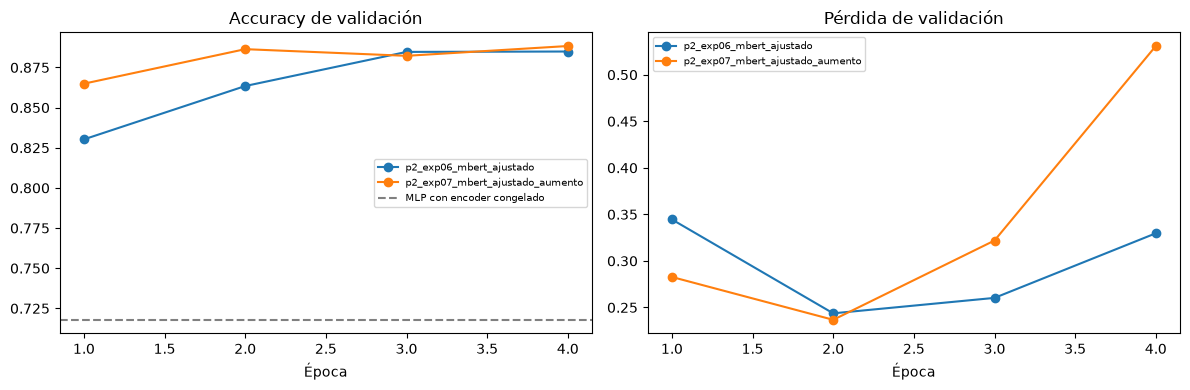

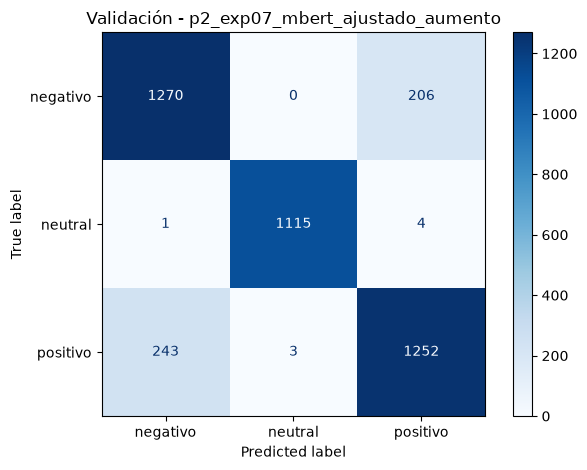

Errores del idioma estimado: en


,id,text,label,prediccion
13,45,The suction power on this vacuum genuinely sur...,positivo,negativo
39,192,The light output is excellent for late-night r...,negativo,positivo
44,213,"I got it on sale a couple of weeks ago, it arr...",negativo,positivo


Errores del idioma estimado: es


,id,text,label,prediccion
28,104,"Me llegó el reloj el martes, dos días después ...",negativo,positivo
33,157,Lo compré hace un par de semanas por internet ...,negativo,positivo
50,237,"Me llegó el parlante el martes pasado, lo comp...",positivo,negativo


Errores del idioma estimado: fr


,id,text,label,prediccion
187,1030,La friteuse à air chauffe vite et les frites s...,negativo,positivo
258,1395,Je l'ai achetée à la mi-année et elle m'est ar...,positivo,negativo
426,2270,"Je l'ai commandé récemment en promo, il a mis ...",positivo,negativo


Errores del idioma estimado: pt


,id,text,label,prediccion
2,6,Comprei há umas duas semanas pela internet e c...,negativo,positivo
57,270,Comprei essa licuadora mês passado pro café da...,negativo,positivo
71,332,Compré essa mala pra viagem de férias em dezem...,positivo,negativo


El mejor ajuste obtuvo **0.88837** en la misma validación, un cambio de **+17.05 puntos** frente al MLP congelado. El efecto del aumento fue **+0.34 puntos** al comparar la misma arquitectura. El resultado público nuevo todavía debe verificarse en Kaggle. Los idiomas son estimados; los cuatro ejemplos marcados como mezcla no permiten generalizar a todas las reseñas mixtas.

In [10]:
if __name__ == "__main__":
    main()
    analizar_resultados()


# Análisis de la mejora de la parte 2

Ejecución del 18 de noviembre de 2026. Se conservaron exactamente los 4.094 IDs de validación
de la primera versión. El score público anterior informado por el grupo es **0,70383**.
Las cifras siguientes son de validación interna y no sustituyen un envío a Kaggle.

| Modelo | Accuracy local | Aciertos / 4.094 |
| --- | ---: | ---: |
| mBERT congelado + MLP, candidato anterior | 0,71788 | 2.939 |
| mBERT ajustado + MLP, sin aumento | 0,88495 | 3.623 |
| mBERT ajustado + MLP, con aumento | **0,88837** | **3.637** |

La mejora frente al modelo congelado fue de **17,05 puntos porcentuales**. Se corrigieron
904 errores del modelo anterior y se perdieron 206 aciertos: el balance fue de 698 aciertos
adicionales. Los errores totales bajaron de 1.155 a 457. La mayor mejora proviene del ajuste
de las capas contextuales, no de un gran aumento en el tamaño de la cabeza de clasificación.
La cabeza conserva dos capas ocultas, de 128 y 64 neuronas.

## Efecto del aumento y selección

Con el mismo entrenamiento y arquitectura, el aumento pasó de 0,88495 a 0,88837: 14 aciertos
netos adicionales, equivalentes a **0,34 puntos porcentuales**. El efecto es pequeño frente
al cambio del encoder congelado al ajustado. Solo se aumentaron reseñas de entrenamiento;
no se aumentaron ni entrenaron las de validación durante esta comparación.

Se probaron también mezclas de las probabilidades de ambos candidatos. La mezcla al 50%
obtuvo 0,88691; las mezclas al 25% y al 75% tampoco superaron el modelo aumentado individual.
Se mantuvo por tanto un solo modelo, con mayor accuracy local y menor costo de inferencia.

En el modelo aumentado, la accuracy pasó de 0,88642 en la época 2 a 0,88837 en la época 4.
La pérdida, en cambio, subió de 0,23673 a 0,53087. Esto muestra sobreajuste y exceso de confianza
en algunos errores, aunque se ganaron ocho aciertos. Se seleccionó la época 4 por la métrica
oficial de accuracy. No se interpreta la elevada accuracy de entrenamiento como evidencia
de generalización. La mejora de la época 4 sobre la 2 es pequeña y depende de esta partición.

## Idiomas estimados

| Grupo estimado | Casos | Accuracy del modelo elegido |
| --- | ---: | ---: |
| Inglés | 472 | 84,53% |
| Español | 2.732 | 90,48% |
| Francés | 419 | 84,01% |
| Portugués | 467 | 87,79% |
| Mezcla ES/EN detectada | 4 | 100,00% |

Los cuatro ejemplos del último grupo no representan todas las mezclas del conjunto.
La reseña 3636 mezcla español e inglés y fue agrupada como español. El clasificador recibe
directamente el texto; estas estimaciones se usan para la partición y el diagnóstico.

## Ejemplos que cambiaron y errores restantes

- **Español, ID 1026:** critica la nitidez de imagen y después elogia el motor mediante una
  concesión. Su etiqueta es positiva. El modelo congelado predijo negativo y el ajustado
  predijo positivo.
- **Inglés, ID 6339:** el elogio al motor convive con una crítica al cargador. Su etiqueta es
  negativa. El modelo ajustado corrigió la predicción positiva del modelo anterior.
- **Francés, ID 6265:** el soporte resolvió el problema y el texto declara que no tiene ninguna
  queja. Su etiqueta es positiva. El modelo anterior predijo negativo y el nuevo positivo.
  En el ID 10308, la devolución al servicio técnico y el abandono del uso también se clasifican
  ahora como negativos, pese a los elogios intermedios.
- **Portugués, ID 4907:** contiene negaciones como «Não é que eu goste» y «Não diria que o preço
  é bom». El modelo elegido todavía predice positivo frente a la etiqueta negativa. El ajuste
  sin aumento sí acertaba este caso: una mayor accuracy global no implica corregir todos los
  mismos ejemplos.
- **Inglés, ID 45, y francés, ID 1030:** combinan ventajas, problemas y una conclusión indecisa.
  Persisten errores cuando el sentimiento global es indirecto o ambas polaridades tienen
  bastante presencia. Se conservan las etiquetas originales del conjunto.
- **Español, ID 104, y portugués, ID 6:** una crítica fuerte se combina con una frase posterior
  positiva o moderada. El modelo todavía puede dar demasiado peso a esa parte final.

La matriz de confusión tiene 206 negativos predichos como positivos y 243 positivos predichos
como negativos. La clase neutral registra 1.115 aciertos de 1.120 casos. Distinguir las dos
polaridades sigue siendo más difícil que reconocer reseñas descriptivas.

## Reentrenamiento y límites

Para el candidato completo se usan las 20.466 reseñas originales de train y 10.227 copias
tipográficas. Se vuelve al modelo preentrenado inicial y se repite el entrenamiento por las
cuatro épocas seleccionadas. Este ajuste final incorpora también los registros antes reservados
para validación, por lo que no se utiliza esa misma partición para atribuirle otra accuracy.

El CSV `particion80` corresponde al checkpoint realmente medido sobre la validación reservada.
El CSV `full` corresponde al reentrenamiento con todo train. Los dos provienen de modelos
guardados y recargados. Los resultados públicos nuevos quedan pendientes de Kaggle.

La comparación usa una sola semilla y una sola partición. Los idiomas son estimados, el aumento
puede introducir ruido y la distribución de eval puede ser distinta de train. No se usan los
textos de eval para entrenamiento, adaptación del encoder, aumento ni selección de épocas.
